In [2]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score


In [4]:
data=sns.load_dataset("mpg")
data=data[['displacement','mpg']]
data.head(10)

,displacement,mpg
0,307.0,18.0
1,350.0,15.0
2,318.0,18.0
3,304.0,16.0
4,302.0,17.0
5,429.0,15.0
6,454.0,14.0
7,440.0,14.0
8,455.0,14.0
9,390.0,15.0


In [5]:
data.dropna(inplace=True)

In [7]:
data.head(10)

,displacement,mpg
0,307.0,18.0
1,350.0,15.0
2,318.0,18.0
3,304.0,16.0
4,302.0,17.0
5,429.0,15.0
6,454.0,14.0
7,440.0,14.0
8,455.0,14.0
9,390.0,15.0


In [8]:
x=data['displacement'].values
y=data['mpg'].values

In [10]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=42)


In [12]:
x_train_poly=np.column_stack((
    np.ones(len(x_train)),
    x_train,
    x_train**2
))
x_test_poly=np.column_stack((
    np.ones(len(x_test)),
    x_test,
    x_test**2
))

In [13]:
theta=np.linalg.inv(x_train_poly.T @ x_train_poly) @(x_train_poly.T @ y_train)

In [14]:
y_pred=x_test_poly @ theta
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(theta)
print("MSE:",mse)
print("R2 Score:",r2)

[ 4.21989052e+01 -1.38279492e-01  1.67631984e-04]
MSE: 15.107353561081089
R2 Score: 0.7190189176110222


In [18]:
x_line=np.linspace(x.min(),x.max(),300)
x_poly=np.column_stack((
    np.ones(len(x_line)),
    x_line,x_line**2
))

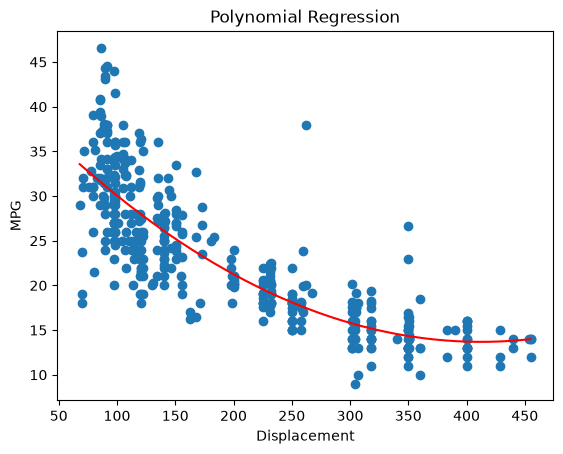

In [20]:
y_line=x_poly @theta
plt.scatter(x,y)
plt.plot(x_line,y_line,color="red")
plt.xlabel("Displacement")
plt.ylabel("MPG")
plt.title("Polynomial Regression")
plt.show()